<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-Julian Lizarazo
-Kevin Albarracin

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [1]:
### TU CÓDIGO AQUÍ ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

In [2]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [6]:
### TU CÓDIGO AQUÍ ###
df_indicators = pd.read_csv('/content/drive/MyDrive/Talleres de IA/Indicators.csv')
df_indicators.head()

,CountryCode,IndicatorCode,Year,Value
0,CHL,NV.AGR.TOTL.ZS,2014,6.75
1,CHL,NE.TRD.GNFS.ZS,2014,74.31
2,CHL,NY.GDP.MKTP.KD.ZG,2014,7.65
3,CHL,FP.CPI.TOTL.ZG,2014,12.62
4,CHL,GC.DOD.TOTL.GD.ZS,2014,42.83


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [8]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [9]:
### TU CÓDIGO AQUÍ ###
df_countries = pd.read_csv('/content/drive/MyDrive/Talleres de IA/Country.csv')
df_countries.head()

,CountryCode,ShortName,Region
0,CHL,Chile,Latin America & Caribbean
1,PAN,Panamá,Latin America & Caribbean
2,CRI,Costa Rica,Latin America & Caribbean
3,COL,Colombia,Latin America & Caribbean
4,PER,Perú,Latin America & Caribbean


In [10]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [11]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [12]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [13]:
### TU CÓDIGO AQUÍ ###
df_indicators['IndicatorName'] = df_indicators['IndicatorCode'].map(nombre_indicadores)
df_indicators.head()

,CountryCode,IndicatorCode,Year,Value,IndicatorName
0,CHL,NV.AGR.TOTL.ZS,2014,6.75,Agricultura (% del PIB)
1,CHL,NE.TRD.GNFS.ZS,2014,74.31,Comercio (% del PIB)
2,CHL,NY.GDP.MKTP.KD.ZG,2014,7.65,Crecimiento del PIB (%)
3,CHL,FP.CPI.TOTL.ZG,2014,12.62,Inflación (%)
4,CHL,GC.DOD.TOTL.GD.ZS,2014,42.83,Deuda del gob. central (% del PIB)


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [14]:
### TU CÓDIGO AQUÍ ###
df_pivot = df_indicators.pivot_table(index='CountryCode', columns='IndicatorName', values='Value').reset_index()
df_pivot.head()

IndicatorName,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [15]:
### TU CÓDIGO AQUÍ ###
df_final = pd.merge(df_pivot, df_countries, on='CountryCode')
df_final.head()

,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),ShortName,Region
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina,Latin America & Caribbean
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,Bolivia,Latin America & Caribbean
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil,Latin America & Caribbean
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,Latin America & Caribbean
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,Latin America & Caribbean


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [16]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.drop(columns=['Region', 'CountryCode'])
df_final = df_final.set_index('ShortName')
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
ShortName,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61


### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [17]:
### TU CÓDIGO AQUÍ ###
df_final.isnull().sum() / len(df_final) * 100

,0
Agricultura (% del PIB),28.57
Comercio (% del PIB),21.43
Crecimiento del PIB (%),0.00
Deuda del gob. central (% del PIB),28.57
Días para cumplir contratos,14.29
Exportaciones (US$),21.43
Facilidad para hacer negocios,35.71
Gasto en educación (% del PIB),21.43
Gasto en salud (% del PIB),28.57
Importaciones (US$),21.43


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [18]:
### TU CÓDIGO AQUÍ ###
df_final_imputed = df_final.copy()

for col in df_final_imputed.columns:
    df_final_imputed[col].fillna(df_final_imputed[col].mean(), inplace=True)
    print(f"Valores faltantes en {col}: {df_final_imputed[col].isnull().sum()}")

Valores faltantes en Agricultura (% del PIB): 0
Valores faltantes en Comercio (% del PIB): 0
Valores faltantes en Crecimiento del PIB (%): 0
Valores faltantes en Deuda del gob. central (% del PIB): 0
Valores faltantes en Días para cumplir contratos: 0
Valores faltantes en Exportaciones (US$): 0
Valores faltantes en Facilidad para hacer negocios: 0
Valores faltantes en Gasto en educación (% del PIB): 0
Valores faltantes en Gasto en salud (% del PIB): 0
Valores faltantes en Importaciones (US$): 0
Valores faltantes en Inflación (%): 0


/tmp/ipykernel_1234/3661440282.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_final_imputed[col].fillna(df_final_imputed[col].mean(), inplace=True)


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

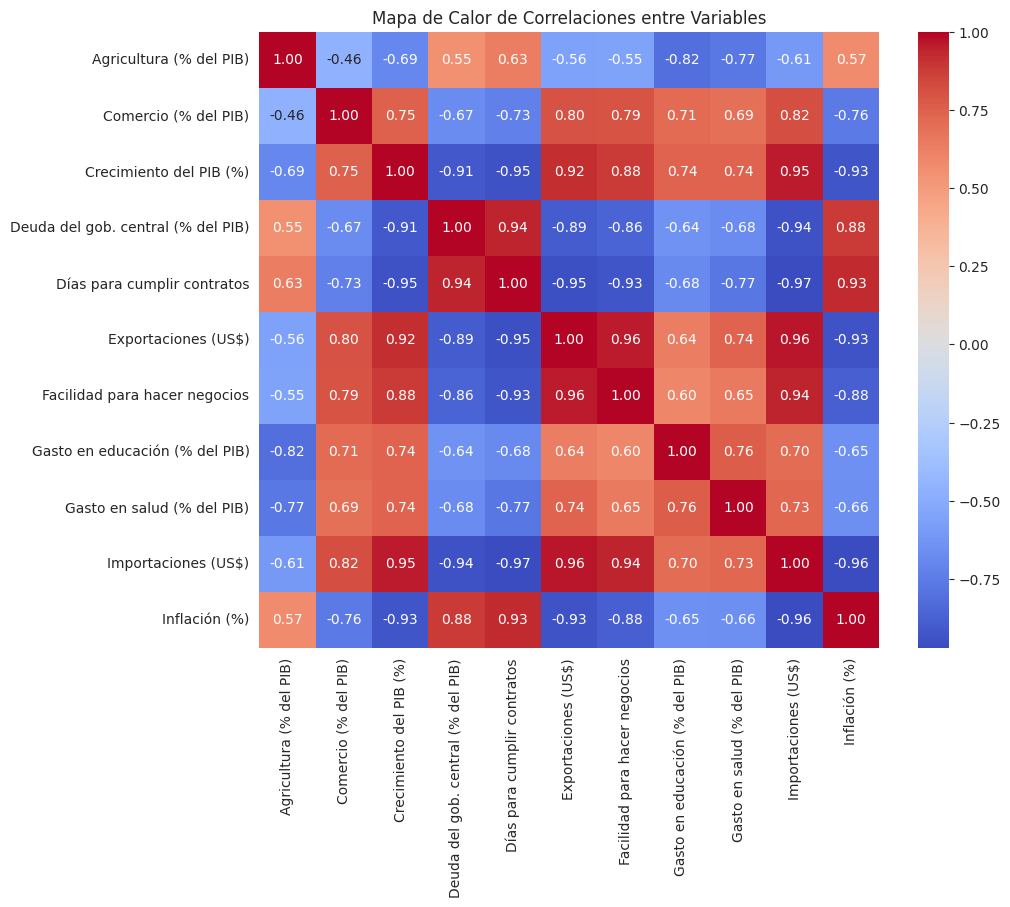

In [19]:
### TU CÓDIGO AQUÍ ###
corr_matrix = df_final_imputed.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlaciones entre Variables')
plt.show()


4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [20]:
### TU CÓDIGO AQUÍ ###
x_scaled = (df_final_imputed - df_final_imputed.mean()) / df_final_imputed.std()
x_scaled.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
ShortName,,,,,,,,,,,
Argentina,1.51,-2.24,-1.50,1.37,1.59,-1.62,-1.40,-2.71,-2.09,-1.62,1.61
Bolivia,-0.00,-0.16,-0.68,0.76,0.91,-0.78,0.00,0.19,-1.16,-0.71,1.00
Brasil,2.07,0.39,-0.37,-0.15,0.38,-0.02,-0.31,-0.59,-0.91,-0.08,0.22
Chile,-1.11,1.73,1.51,-1.52,-1.51,1.51,1.52,1.18,1.98,1.39,-0.74
Colombia,-1.02,0.37,1.12,-1.03,-0.61,0.00,0.00,1.14,0.05,0.76,-0.81


In [21]:
from sklearn.preprocessing import StandardScaler
scaler_wine = StandardScaler()
x_scaled = scaler_wine.fit_transform(df_final_imputed)

### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [22]:
### TU CÓDIGO AQUÍ ###

pca = PCA()
pca.fit(x_scaled)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

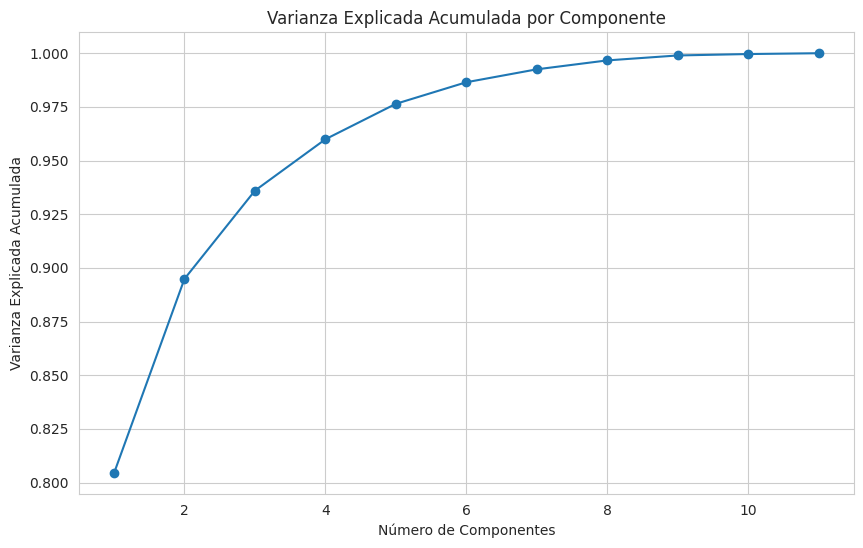

In [23]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='-')
plt.title('Varianza Explicada Acumulada por Componente')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid(True)
plt.show()

5.3. Realiza un análisis del gráfico anterior.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [24]:
### TU CÓDIGO AQUÍ ###

pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(x_scaled)

print("Forma de X_pca:", X_pca.shape)
print("Primeras filas de X_pca:",X_pca.shape)
print(X_pca[:5])

Forma de X_pca: (14, 1)
Primeras filas de X_pca: (14, 1)
[[-5.93163943]
 [-1.93288957]
 [-1.24450158]
 [ 4.89445994]
 [ 2.13036856]]


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

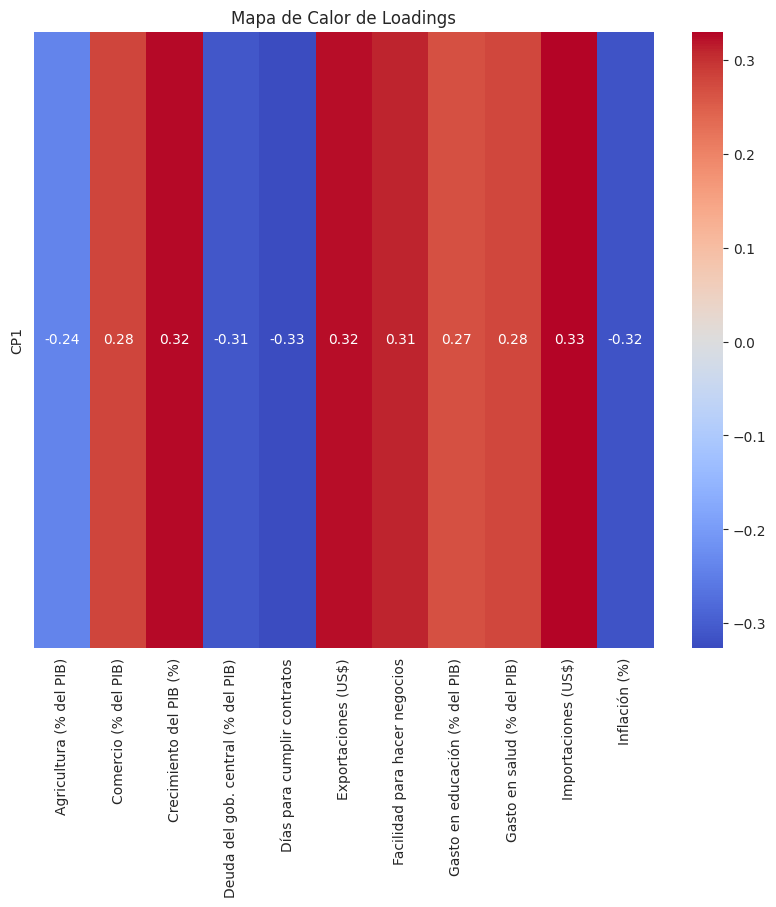

In [27]:
### TU CÓDIGO AQUÍ ###
df_wine_loadings = pd.DataFrame(pca_final.components_,
                                columns=df_final_imputed.columns,
                                index=['CP1'])

plt.figure(figsize=(10, 8))
sns.heatmap(df_wine_loadings, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Loadings')
plt.show()

6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [28]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [29]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.sort_values(by='Indice_Inversion', ascending=False)
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.2. Convierte 'ShortName' en una columna del dataframe.

In [30]:
### TU CÓDIGO AQUÍ ###
df_final.reset_index(inplace=True)
df_final.head()

,ShortName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
0,Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
1,Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
2,Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
3,Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
4,Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

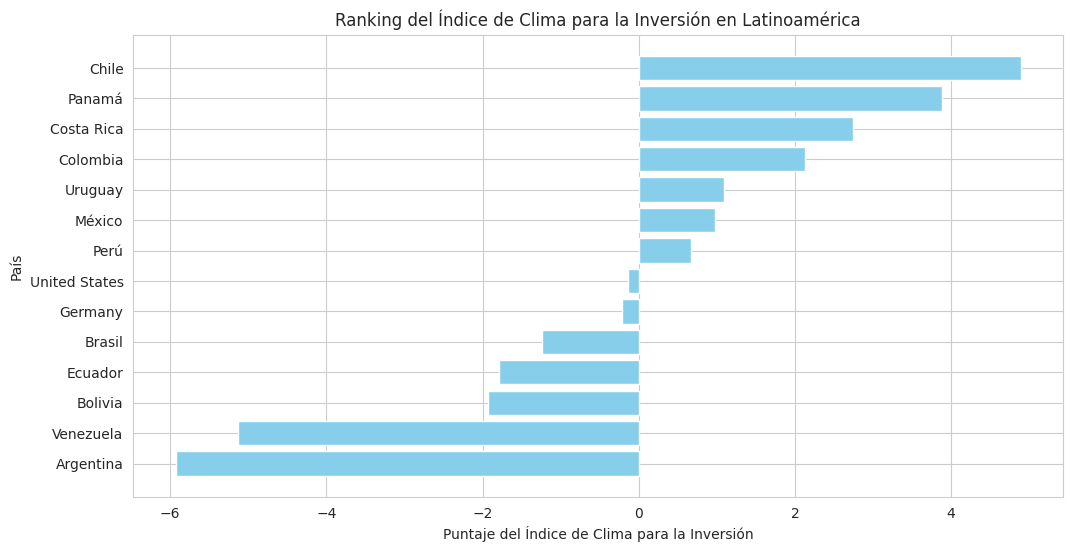

In [33]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(12, 6))
plt.barh(df_final['ShortName'], df_final['Indice_Inversion'], color='skyblue')
plt.xlabel('Puntaje del Índice de Clima para la Inversión')
plt.ylabel('País')
plt.title('Ranking del Índice de Clima para la Inversión en Latinoamérica')
plt.gca().invert_yaxis()  # Muestra el de mayor puntaje arriba
plt.show()

7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

Al mirar los resultados del índice se nota de una que el clima de inversión en Latinoamérica está súper fragmentado y que a Colombia, aunque lidera cómodamente el grupo medio en el cuarto lugar con un puntaje positivo de 2.13, todavía le falta bastante para alcanzar al lote de líderes que son Chile, Panamá y Costa Rica. Estos tres países son nuestros verdaderos competidores directos en la atracción de capitales extranjeros porque nos llevan la delantera en factores institucionales y de infraestructura clave; por ejemplo, Chile nos gana de lejos con un sistema legal súper ágil que reduce la incertidumbre en los contratos y con una fuerza laboral muy bien calificada gracias a años de alta inversión social, mientras que Panamá nos desplaza por su brutal apertura comercial y estabilidad macro, y Costa Rica se consolida como un hub tecnológico preferido gracias a su facilidad para hacer negocios y su capital humano enfocado en servicios de alto valor. Para que podamos competirles de tú a tú, el MinCIT tiene que meterle la ficha urgente a recortar la asfixiante tramitología y los tiempos de espera en los juzgados, además de priorizar incentivos que de verdad ayuden a diversificar nuestra canasta exportadora y a sofisticar la educación técnica en áreas que demanden las empresas de afuera.